# Listed credit ratios

## What OneCredit uses this for

OneCredit sells a company check. A customer looks up another Malaysian company before extending a trade limit or credit. On a Bursa issuer this notebook is that check's financial page.

- The median current ratio says whether the issuer can pay its current liabilities.
- Liabilities / assets says how much of the asset base is other people's money.
- The net margin and the Altman Z″ zone say whether that structure is earning a profit, and whether the score sits in the distress band below 1.1.
- The sector table is the peer rank. A limit is read against the issuer's own sector, not against the whole market.
- The mean net margin stays on the page because the left tail pulls it below the median. A limit set on the mean follows that tail.

A counterparty file on a Bursa issuer starts from the latest balance sheet and income statement. The questions are whether the company can pay its current liabilities, how much of the asset base is financed by liabilities, whether that structure is earning a profit, and where the company sits against its own sector.

```text
balance_sheet.csv -- registration_number + fiscal_date --+
income.csv        -- same keys                           +--> latest-year ratios --> sector ranks
company_profile.csv -- registration_number, sector       +
```

Amounts in `data/balance_sheet.csv` and `data/income.csv` are RM millions. Maybank FY2024 revenue is stored as 27,907, which is RM 27.9 billion. Banks and the rest of the Financials sector stay out of the industrial ratios: a deposit book is not working capital.

Altman Z″ here is the four-ratio emerging-market score, without the 3.25 location constant:

Z″ = 6.56 X₁ + 3.26 X₂ + 6.72 X₃ + 1.05 X₄

- X₁ = working capital / total assets
- X₂ = retained earnings / total assets
- X₃ = operating income / total assets, the EBIT proxy on this extract
- X₄ = book equity / total liabilities

Zones: Z″ above 2.6 is safe, 1.1 to 2.6 is grey, below 1.1 is distress. Medians lead the summaries because these ratios are skewed. A mean pulled by a handful of issuers is a poor credit limit.


In [1]:
%matplotlib inline
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

NOTEBOOK_DIR = Path.cwd()
if not (NOTEBOOK_DIR / "credit_stats.py").exists():
    NOTEBOOK_DIR = Path.cwd() / "notebooks" / "credit_desk"
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

from credit_stats import (
    DATA_DIR,
    FIGURE_DIR,
    FINANCIAL_SECTOR_NAME,
    INSTITUTIONAL_INVESTOR_TYPES,
    LISTED_AMOUNT_UNIT,
    SSM_AMOUNT_UNIT,
    build_listed_panel,
    clean_state_name,
    age_in_years,
    cramers_v,
    distribution_row,
    epsilon_squared,
    herfindahl_from_positive_amounts,
    latest_rows,
    load_listed_statements,
    ownership_fraction,
    parse_ssm_financials,
    parse_ssm_profiles,
    peer_percentile,
    share_with_interval,
)

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 120)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")


In [2]:
statements = load_listed_statements()
panel = build_listed_panel(statements)
latest = latest_rows(panel, "registration_number", "fiscal_date")

# Industrial file: drop Financials before liquidity and Z″.
operating_latest = latest.loc[~latest["is_financial_sector"]].copy()
# Unknown is a failed profile join, not a Bursa sector, so it gets no peer rank.
peer_sector = operating_latest["sector"].where(operating_latest["sector"].ne("Unknown"))
operating_latest["net_margin_peer_percentile"] = peer_percentile(
    operating_latest["net_profit_margin"], peer_sector
)

print(f"Statement years in the joined panel: {len(panel):,}")
print(f"Issuers with a latest joined year: {latest['registration_number'].nunique():,}")
print(f"Of which outside {FINANCIAL_SECTOR_NAME}: {operating_latest['registration_number'].nunique():,}")
print(f"Industrial issuers with no sector on the profile join: {(operating_latest['sector'] == 'Unknown').sum():,}")
print(f"Amount unit: {LISTED_AMOUNT_UNIT}")
print(f"Latest fiscal dates from {operating_latest['fiscal_date'].min().date()} to {operating_latest['fiscal_date'].max().date()}")


Statement years in the joined panel: 5,108
Issuers with a latest joined year: 1,087
Of which outside Financials: 1,049
Industrial issuers with no sector on the profile join: 83
Amount unit: RM millions
Latest fiscal dates from 2023-11-30 to 2024-12-31


## Cross-section of the latest year

Each ratio below is one number per issuer, using the latest fiscal date that has both a balance sheet and an income statement. Skew above zero means a long right tail. The MAD outlier share is the fraction whose modified z-score exceeds 3.5, so the tail is measured without letting the tail define the centre.


In [3]:
ratio_names = [
    "current_ratio",
    "working_capital_to_assets",
    "liabilities_to_assets",
    "debt_to_equity",
    "gross_margin",
    "operating_margin",
    "net_profit_margin",
    "return_on_assets",
    "return_on_equity",
    "z_double_prime",
]
distribution = pd.DataFrame(
    [distribution_row(operating_latest[ratio_name], ratio_name) for ratio_name in ratio_names]
)
distribution


,ratio,n,median,mean,p25,p75,iqr,skew,excess_kurtosis,mad_outlier_share
0,current_ratio,1035,2.1550,4.7248,1.3571,4.2123,2.8552,13.9423,220.9815,0.1150
1,working_capital_to_assets,1035,0.2594,0.2678,0.0986,0.4489,0.3504,-0.9373,5.6101,0.0077
2,liabilities_to_assets,1036,0.3858,0.4008,0.2122,0.5409,0.3288,1.7158,9.3497,0.0077
3,debt_to_equity,1025,0.2145,0.4758,0.0542,0.5827,0.5285,7.1195,83.0710,0.0995
4,gross_margin,1019,0.2395,0.2608,0.1305,0.3823,0.2517,-10.1283,212.1960,0.0196
5,operating_margin,1033,0.0852,-0.0142,0.0096,0.1708,0.1612,-8.6736,112.6750,0.1171
6,net_profit_margin,1033,0.0531,-0.0747,-0.0113,0.1162,0.1275,-19.3483,490.7835,0.1346
7,return_on_assets,1024,0.0262,0.0114,-0.0053,0.0661,0.0714,-3.1637,19.2638,0.0820
8,return_on_equity,1013,0.0480,0.0084,-0.0062,0.1036,0.1098,-13.9064,283.0503,0.0948
9,z_double_prime,1021,4.6025,6.9343,2.1556,7.8189,5.6633,11.0803,151.1918,0.0529


In [4]:
loss_share = share_with_interval(operating_latest["is_loss_making"])
distress_share = share_with_interval(operating_latest["distress_zone"].eq("distress"))
grey_share = share_with_interval(operating_latest["distress_zone"].eq("grey"))
safe_share = share_with_interval(operating_latest["distress_zone"].eq("safe"))

zone_table = pd.DataFrame(
    [
        {"measure": "loss-making, net income < 0", **loss_share},
        {"measure": "Z″ distress zone", **distress_share},
        {"measure": "Z″ grey zone", **grey_share},
        {"measure": "Z″ safe zone", **safe_share},
    ]
)
zone_table


,measure,successes,trials,share,wilson_low,wilson_high
0,"loss-making, net income < 0",276,1049,0.2631,0.2374,0.2906
1,Z″ distress zone,156,1049,0.1487,0.1285,0.1715
2,Z″ grey zone,146,1049,0.1392,0.1195,0.1614
3,Z″ safe zone,719,1049,0.6854,0.6567,0.7128


## Sector peers

Kruskal-Wallis compares net-profit-margin ranks across sectors. It does not assume a normal margin. ε² is the effect size: (H − k + 1) / (n − k). The distress flag is then crossed with sector in one chi-square table. Cramér's V is reported with the p-value because a few hundred issuers can make a small mix difference look sharp on a p-value alone.

A peer percentile is the issuer's rank inside its sector. Sectors with fewer than five usable margins do not get a percentile.


In [5]:
from scipy.stats import chi2_contingency, kruskal

sector_rows = []
margin_groups = []
sector_names_for_kruskal = []
# Sector tests use labelled Bursa sectors only. Unknown is a missing join.
labelled_latest = operating_latest.loc[operating_latest["sector"].ne("Unknown")]
for sector_name, sector_frame in labelled_latest.groupby("sector"):
    margins = sector_frame["net_profit_margin"].dropna()
    zone_counts = sector_frame["distress_zone"].value_counts()
    known_zone = sector_frame["distress_zone"].notna()
    distress_mask = sector_frame.loc[known_zone, "distress_zone"].eq("distress")
    distress_interval = share_with_interval(distress_mask)
    sector_rows.append(
        {
            "sector": sector_name,
            "issuers": int(sector_frame["registration_number"].nunique()),
            "median_net_margin": float(margins.median()) if len(margins) else float("nan"),
            "median_current_ratio": float(sector_frame["current_ratio"].median()),
            "median_liabilities_to_assets": float(sector_frame["liabilities_to_assets"].median()),
            "median_z_double_prime": float(sector_frame["z_double_prime"].median()),
            "distress_share": distress_interval["share"],
            "distress_wilson_low": distress_interval["wilson_low"],
            "distress_wilson_high": distress_interval["wilson_high"],
            "loss_share": float(sector_frame["is_loss_making"].mean()),
        }
    )
    if len(margins) >= 20:
        margin_groups.append(margins.to_numpy())
        sector_names_for_kruskal.append(sector_name)

sector_summary = pd.DataFrame(sector_rows).sort_values("issuers", ascending=False)
kruskal_result = kruskal(*margin_groups)
kruskal_n = int(sum(len(group) for group in margin_groups))
kruskal_effect = epsilon_squared(
    kruskal_result.statistic, len(margin_groups), kruskal_n
)

distress_by_sector = (
    labelled_latest.loc[labelled_latest["distress_zone"].notna()]
    .assign(is_distress=lambda frame: frame["distress_zone"].eq("distress"))
)
sector_sizes = distress_by_sector.groupby("sector")["registration_number"].nunique()
sectors_for_chi_square = sector_sizes[sector_sizes >= 30].index
chi_square_frame = distress_by_sector.loc[
    distress_by_sector["sector"].isin(sectors_for_chi_square)
]
contingency = pd.crosstab(chi_square_frame["sector"], chi_square_frame["is_distress"])
chi_square_statistic, chi_square_p, chi_square_dof, _expected = chi2_contingency(contingency)
cramer = cramers_v(
    chi_square_statistic,
    int(contingency.to_numpy().sum()),
    contingency.shape[0],
    contingency.shape[1],
)

print(
    f"Kruskal-Wallis on net margin across {len(margin_groups)} sectors: "
    f"H = {kruskal_result.statistic:.2f}, p = {kruskal_result.pvalue:.4g}, "
    f"ε² = {kruskal_effect:.3f}, n = {kruskal_n}"
)
print(
    f"Distress × sector chi-square: χ² = {chi_square_statistic:.2f}, "
    f"df = {chi_square_dof}, p = {chi_square_p:.4g}, Cramér's V = {cramer:.3f}"
)
sector_summary


Kruskal-Wallis on net margin across 9 sectors: H = 27.00, p = 0.0007071, ε² = 0.020, n = 951
Distress × sector chi-square: χ² = 10.74, df = 6, p = 0.09667, Cramér's V = 0.110


,sector,issuers,median_net_margin,median_current_ratio,median_liabilities_to_assets,median_z_double_prime,distress_share,distress_wilson_low,distress_wilson_high,loss_share
5,Industrials,250,0.0498,2.0099,0.4300,4.3602,0.1829,0.1396,0.2360,0.2520
1,Consumer Cyclicals,150,0.0388,2.4039,0.3347,5.5444,0.1351,0.0892,0.1995,0.3067
2,Consumer Non-Cyclicals,126,0.0791,2.4634,0.3179,5.8204,0.0976,0.0567,0.1628,0.1349
7,Technology,124,0.0372,2.8710,0.2914,5.3562,0.2119,0.1478,0.2941,0.3710
0,Basic Materials,123,0.0341,2.1550,0.3298,4.6398,0.1043,0.0607,0.1736,0.2846
6,Others,106,0.0875,2.0081,0.4072,3.6473,0.1333,0.0811,0.2114,0.2547
4,Healthcare,37,0.0294,3.2556,0.2227,6.9501,0.1714,0.0810,0.3268,0.4054
3,Energy,30,0.0717,1.3925,0.5751,3.0044,0.3103,0.1728,0.4923,0.1667
8,Utilities,20,0.0772,1.7501,0.5729,3.3507,0.0500,0.0089,0.2361,0.2000


In [6]:
from scipy.stats import spearmanr

rank_columns = [
    "current_ratio",
    "liabilities_to_assets",
    "net_profit_margin",
    "return_on_assets",
    "z_double_prime",
]
spearman_rows = []
for left_index, left_name in enumerate(rank_columns):
    for right_name in rank_columns[left_index + 1 :]:
        pair = operating_latest[[left_name, right_name]].dropna()
        rho, p_value = spearmanr(pair[left_name], pair[right_name])
        spearman_rows.append(
            {
                "left": left_name,
                "right": right_name,
                "n": len(pair),
                "spearman_rho": rho,
                "p_value": p_value,
            }
        )
spearman_table = pd.DataFrame(spearman_rows).sort_values("spearman_rho", key=lambda column: column.abs(), ascending=False)
spearman_table


,left,right,n,spearman_rho,p_value
3,current_ratio,z_double_prime,1021,0.8562,0.0000
7,net_profit_margin,return_on_assets,1022,0.8561,0.0000
6,liabilities_to_assets,z_double_prime,1021,-0.8298,0.0000
0,current_ratio,liabilities_to_assets,1034,-0.7970,0.0000
9,return_on_assets,z_double_prime,1021,0.4477,0.0000
8,net_profit_margin,z_double_prime,1020,0.4447,0.0000
1,current_ratio,net_profit_margin,1021,0.2876,0.0000
2,current_ratio,return_on_assets,1022,0.2418,0.0000
4,liabilities_to_assets,net_profit_margin,1021,-0.2115,0.0000
5,liabilities_to_assets,return_on_assets,1023,-0.1391,0.0000


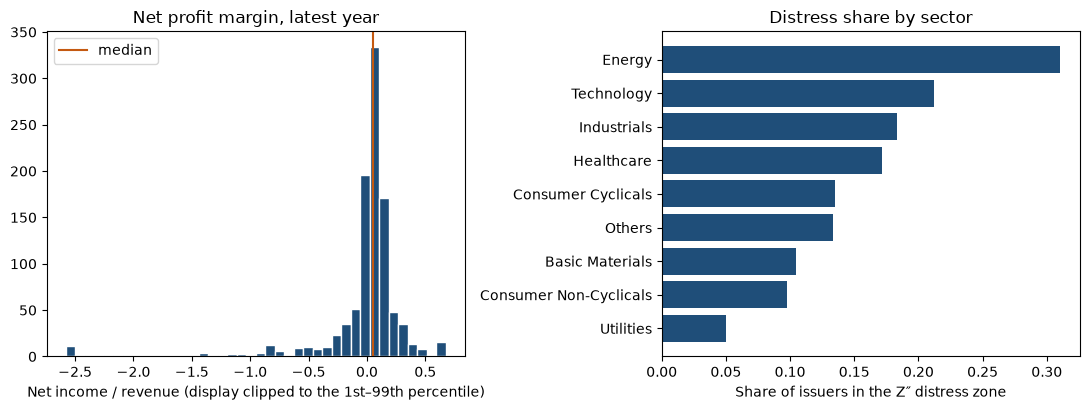

In [7]:
figure, axes = plt.subplots(1, 2, figsize=(11, 4.2))

margin_for_plot = operating_latest["net_profit_margin"].dropna()
lower_display, upper_display = margin_for_plot.quantile([0.01, 0.99])
axes[0].hist(
    margin_for_plot.clip(lower_display, upper_display),
    bins=40,
    color="#1f4e79",
    edgecolor="white",
)
axes[0].axvline(margin_for_plot.median(), color="#c45911", linewidth=1.5, label="median")
axes[0].set_title("Net profit margin, latest year")
axes[0].set_xlabel("Net income / revenue (display clipped to the 1st–99th percentile)")
axes[0].legend()

distress_plot = sector_summary.sort_values("distress_share", ascending=True)
axes[1].barh(distress_plot["sector"], distress_plot["distress_share"], color="#1f4e79")
axes[1].set_xlabel("Share of issuers in the Z″ distress zone")
axes[1].set_title("Distress share by sector")
figure.tight_layout()
figure.savefig(FIGURE_DIR / "01_listed_credit_ratios.png", dpi=140)
plt.show()


In [8]:
median_margin = operating_latest["net_profit_margin"].median()
mean_margin = operating_latest["net_profit_margin"].mean()
median_current = operating_latest["current_ratio"].median()
median_leverage = operating_latest["liabilities_to_assets"].median()
median_z = operating_latest["z_double_prime"].median()
ranked_margin = operating_latest["net_margin_peer_percentile"].dropna()
weak_peer = ranked_margin.lt(0.10).mean()

print("Findings, industrial issuers, latest joined fiscal year")
print(f"  Issuers: {operating_latest['registration_number'].nunique():,}")
print(f"  Median current ratio {median_current:.2f}. Median liabilities/assets {median_leverage:.2f}.")
print(
    f"  Median net margin {median_margin:.3f} against a mean of {mean_margin:.3f}. "
    "The gap is the skew; a limit set on the mean follows the tail."
)
print(
    f"  Loss-making share {loss_share['share']:.1%} "
    f"(Wilson {loss_share['wilson_low']:.1%}–{loss_share['wilson_high']:.1%}, n = {loss_share['trials']})."
)
print(
    f"  Z″ distress share {distress_share['share']:.1%} "
    f"(Wilson {distress_share['wilson_low']:.1%}–{distress_share['wilson_high']:.1%}). "
    f"Median Z″ {median_z:.2f}."
)
print(
    f"  Net-margin ranks differ by sector (Kruskal ε² = {kruskal_effect:.3f}). "
    f"Distress mix across sectors has Cramér's V = {cramer:.3f}."
)
print(
    f"  Share of issuers below the 10th percentile of their own sector's net margin: {weak_peer:.1%}. "
    "With percentile ranks this sits near 10% wherever a sector has enough peers; "
    "the sector table is the part that changes a limit."
)


Findings, industrial issuers, latest joined fiscal year
  Issuers: 1,049
  Median current ratio 2.16. Median liabilities/assets 0.39.
  Median net margin 0.053 against a mean of -0.075. The gap is the skew; a limit set on the mean follows the tail.
  Loss-making share 26.3% (Wilson 23.7%–29.1%, n = 1049).
  Z″ distress share 14.9% (Wilson 12.8%–17.2%). Median Z″ 4.60.
  Net-margin ranks differ by sector (Kruskal ε² = 0.020). Distress mix across sectors has Cramér's V = 0.110.
  Share of issuers below the 10th percentile of their own sector's net margin: 9.4%. With percentile ranks this sits near 10% wherever a sector has enough peers; the sector table is the part that changes a limit.
